- By: OLiver Tschudi Madsen
- GitHub Repository: https://github.com/OTMadsen/IND320
- Streamlit App: ind320-4eqw3p5dwcvvqtwfndtuwa.streamlit.app
- Screencast (YouTube): https://youtu.be/O85VHR85kso

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO
import numpy as np

ASSIGNMENT OVERVIEW

This notebook extends the Norwegian Hydro Reservoir Dashboard by investigating time-series data from multiple sources and developing a reservoir forecasting model using the River's SNARIMAX algorithm. 

AI USE

I consulted some help from CHATgpt to help me with the backtesting for some development of the SNARIMAX model. This was all due to my somewhat lacking skills in making these types of models, and ensuring it worked as it should. It was primarily used for error searching and correction, and every bit of code produced as been thorougly tested and validated by me. 

LOG


The first thing I did was to define the function for the currency exchange. This was simply done by making a function limited by two dates and using the api from Norges Bank to make the currency cell. With existing csv-data, and some coding magic, the function checked out, and printed out a plot for both the Euro and the Dollar. 

Furthermore I investigated the time issue for the different data sources, which has own different markdowns that explains the issue and the solution. 

After that I started on the River Forecast, where I encountered some issues with first draft of the model. The baseline was quite different from the predicted values, so I did some further backtesting to improve the accuracy. This is also displayed further down in the notebook. 

STREAMLIT 

Until assignment 2 I made everything in one local app which I ran through GitHub. This was working fine until I realized that it would look very unorganized, and in the end would just about impossible to maintain. With some help from AI, I figured out a much better solution to organize everything. Rather than keeping everything in one app, it would make more sense to divide it all up, for easier interpretation, and even easier editing. So in, the end, the layout looked something the picture below.

ASSIGNMENT OVERVIEW

This notebook extends the Norwegian Hydro Reservoir Dashboard by investigating time-series data from multiple sources and developing a reservoir forecasting model using the River's SNARIMAX algorithm. 

AI USE

I consulted some help from CHATgpt to help me with the backtesting for some development of the SNARIMAX model. This was all due to my somewhat lacking skills in making these types of models, and ensuring it worked as it should. It was primarily used for error searching and correction, and every bit of code produced as been thorougly tested and validated by me. 



More of the log continues further down in the notebook!

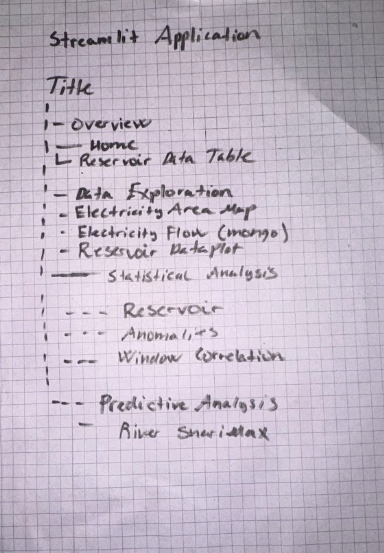

In [2]:
#Here we define the exchange-rate download function using the Norwegian Bank API. 

def download_exchange_rates(start_date, end_date):

    """
    With the API from the Norwegian Bank, we will be able to see the exhange rates for EUR/NOR
    and USD/NOK.

    We define a start-date and an end_date to have an interval to work with. Pusing pandas and its timestamp 
    we will be able to see the values for the currencies. 

    """


    base_url = "https://data.norges-bank.no/api/data/EXR"


# https://www.norges-bank.no/tema/statistikk/apne-data/veiledning-til-norges-banks-datatorg/

    currencies = ["EUR", "USD"]
    frames = []

    start = pd.Timestamp(start_date)
    end = pd.Timestamp(end_date)

    params = {
            "format": "csv",
            "startPeriod": start.strftime("%Y-%m-%d"),
            "endPeriod": end.strftime("%Y-%m-%d"),
            "locale": "en"
        }

    for currency in currencies:

        url = f"{base_url}/B.{currency}.NOK.SP"

        params = {
            "format": "csv",
            "startPeriod": start.strftime("%Y-%m-%d"),
            "endPeriod": end.strftime("%Y-%m-%d"),
            "locale": "en"
        }

        response = requests.get(
            url, 
            params=params,
            timeout=60
        )

        response.raise_for_status()

        df = pd.read_csv(
            StringIO(response.text),
            sep=";",
            encoding="utf-8-sig"
        )

        required = {"TIME_PERIOD", "OBS_VALUE"}


        if not required.issubset(df.columns):
            raise ValueError(
                f"Unexpected API response for {currency}:"
                f"{df.columns.tolist()}"
            )

        df = df[["TIME_PERIOD", "OBS_VALUE"]].copy()

        df = df.rename(columns={
            "TIME_PERIOD": "Date",
            "OBS_VALUE" : f"{currency}_NOK"
        })
    

        frames.append(df)

    exchange_rates = pd.merge(
        frames[0],
        frames[1],
        on="Date",
        how="outer"
    )
    exchange_rates = (
        exchange_rates
        .sort_values("Date")
        .reset_index(drop=True)
    )

    return exchange_rates

        


# This function will be able to loop through both the EUR and USD-currencies and also downloads both of the series from the provided link




In [3]:
#With the function defined, we might as well just test it!

exchange_rates = download_exchange_rates(
    start_date="2024-01-01",
    end_date="2024-12-31"
)

print("Number of observations:", len(exchange_rates))
print("First date", exchange_rates["Date"].min())
print("Last date", exchange_rates["Date"]. max())

display(exchange_rates.head(10))

assert not exchange_rates.empty
assert {"Date", "EUR_NOK", "USD_NOK"}.issubset(
    exchange_rates.columns
)

print("Norges Bank API test run successfully!")

Number of observations: 251
First date 2024-01-02
Last date 2024-12-31


,Date,EUR_NOK,USD_NOK
0,2024-01-02,11.2815,10.2971
1,2024-01-03,11.3200,10.3672
2,2024-01-04,11.2845,10.3027
3,2024-01-05,11.3090,10.3553
4,2024-01-08,11.3620,10.3800
5,2024-01-09,11.3080,10.3364
6,2024-01-10,11.2915,10.3156
7,2024-01-11,11.3283,10.3106
8,2024-01-12,11.2765,10.3057
9,2024-01-15,11.3140,10.3371


Norges Bank API test run successfully!


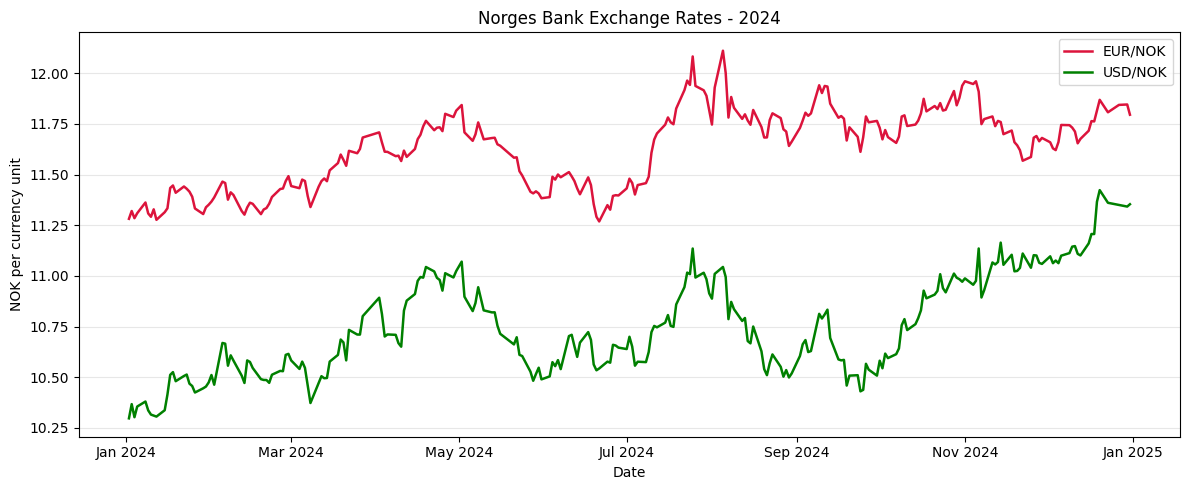

In [4]:
#There occured a couple of images with the dating on the plot, so I used and additional library to fix this issue

import matplotlib.dates as mdates

#Now we convert date strings to actual datetime values

plot_dates = pd.to_datetime(
    exchange_rates["Date"],
    errors="coerce"
)

fig, ax = plt.subplots(figsize=(12,5))

ax.plot(
    plot_dates,
    exchange_rates["EUR_NOK"],
    label="EUR/NOK",
    color="crimson",
    linewidth=1.8
)

ax.plot(
    plot_dates,
    exchange_rates["USD_NOK"],
    label="USD/NOK",
    color="green",
    linewidth=1.8
)

ax.set_title("Norges Bank Exchange Rates - 2024")
ax.set_xlabel("Date")
ax.set_ylabel("NOK per currency unit")

#Here we can show a date label every two months

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
#The next step is to investigate the different time zones for the Magasinstatistikk, ENTSO-E, OpenMeteo and the Bank

"""

These however, does not represent time in the same way, as NVE uses weeks and datesm the ENTSO and
the Open-Meteo are parsed as "UTC" and Norges bank uses dates

This will be displayed now:

"""
import pandas as pd
from zoneinfo import ZoneInfo #used for timezones

NORWAY_TZ = "Europe/Oslo"
UTC_TZ  = "UTC"


example_times = pd.to_datetime(

    [

        "2024-01-15 12:00:00",
        "2024-07-15 12:00:00"
    ],
    utc=True
)

timezone_comparison = pd.DataFrame({
    "UTC" : example_times,
    "Europe/Oslo": example_times.tz_convert(NORWAY_TZ)
})

display(timezone_comparison)

,UTC,Europe/Oslo
0,2024-01-15 12:00:00+00:00,2024-01-15 13:00:00+01:00
1,2024-07-15 12:00:00+00:00,2024-07-15 14:00:00+02:00


In [6]:
#The code above displays the difference here in time since Norway does not always have 24 hour calendar days, e.g. summer and winter times. 

#Further on, we can investigate the time of the year when the days are shorter

def norwegian_days_hours(date):

    start = pd.Timestamp(date).tz_localize(NORWAY_TZ)
    end = start + pd.DateOffset(days=1)

    return int((end.tz_convert("UTC") -
                start.tz_convert("UTC")) / pd.Timedelta(hours=1))


#Now we test for days in the spring, and days in the fall

for date in [

    "2024-03-30",
    "2024-03-31",
    "2024-10-27",
    "2024-10-28"
]:
    print(date, norwegian_days_hours(date), "hours")

2024-03-30 24 hours
2024-03-31 23 hours
2024-10-27 25 hours
2024-10-28 24 hours


In [7]:
#For this project, we can store timestamps in UTC, convert to Norwegian time, with the latter info in mind, and preserve date-only observations as dates

#Now, we reuse the ENTSO and the Open-Meteo


def prepare_hourly_timestamps(df, time_column):
    result = df.copy()

    result["time_utc"] = pd.to_datetime(
        result[time_column],
        utc=True,
        errors="coerce"
    )

    result["time_oslo"] = (
        result["time_utc"].dt.tz_convert("Europe/Oslo")
    )

    result["norwegian_date"] = result["time_oslo"].dt.date

    return result


In [8]:
#We can now test it with the ERA5 for NO3 from assignment 3

weather_no3 = pd.read_csv("NO3_ERA5_for_2024.csv")

weather_prepared = prepare_hourly_timestamps(
    weather_no3,
    time_column="time"
)

display(
    weather_prepared[
        ["time_utc", "time_oslo", "norwegian_date"]
    ].head(10)
)

,time_utc,time_oslo,norwegian_date
0,2024-01-01 00:00:00+00:00,2024-01-01 01:00:00+01:00,2024-01-01
1,2024-01-01 01:00:00+00:00,2024-01-01 02:00:00+01:00,2024-01-01
2,2024-01-01 02:00:00+00:00,2024-01-01 03:00:00+01:00,2024-01-01
3,2024-01-01 03:00:00+00:00,2024-01-01 04:00:00+01:00,2024-01-01
4,2024-01-01 04:00:00+00:00,2024-01-01 05:00:00+01:00,2024-01-01
5,2024-01-01 05:00:00+00:00,2024-01-01 06:00:00+01:00,2024-01-01
6,2024-01-01 06:00:00+00:00,2024-01-01 07:00:00+01:00,2024-01-01
7,2024-01-01 07:00:00+00:00,2024-01-01 08:00:00+01:00,2024-01-01
8,2024-01-01 08:00:00+00:00,2024-01-01 09:00:00+01:00,2024-01-01
9,2024-01-01 09:00:00+00:00,2024-01-01 10:00:00+01:00,2024-01-01


In [9]:
#Now we just handle the Norges Bank data a bit differently, since they operate with different time scaling

exchange_rates_prepared = exchange_rates.copy()

exchange_rates_prepared["Date"] = pd.to_datetime(
    exchange_rates_prepared["Date"],
    errors="coerce"
)

exchange_rates_prepared["norwegian_date"] = (
    exchange_rates_prepared["Date"].dt.date
)

display(
    exchange_rates_prepared[
        ["norwegian_date", "EUR_NOK", "USD_NOK"]
    ].head()
)

print("Norges Bank date type:")
print(exchange_rates["Date"].dtype)

print("\nFirst five observations:")
display(exchange_rates[["Date", "EUR_NOK", "USD_NOK"]].head())



,norwegian_date,EUR_NOK,USD_NOK
0,2024-01-02,11.2815,10.2971
1,2024-01-03,11.3200,10.3672
2,2024-01-04,11.2845,10.3027
3,2024-01-05,11.3090,10.3553
4,2024-01-08,11.3620,10.3800


Norges Bank date type:
object

First five observations:


,Date,EUR_NOK,USD_NOK
0,2024-01-02,11.2815,10.2971
1,2024-01-03,11.3200,10.3672
2,2024-01-04,11.2845,10.3027
3,2024-01-05,11.3090,10.3553
4,2024-01-08,11.3620,10.3800


- The four data sources in the overall project do represent time differently. 

- THE NVE Magasinstatistikk publishes new filling statistics on a weekly basis that is measured on Sunday evenings. There are reference dates, but they are usually published Wednesdays. These must be distingiushed.

- The ENTSO uses API respinse timestamps parsed for the UTC. Norway follows CET during the winter and CEST for the summer, so these has to be converted no Norwegian time to make sense for the following analysis. 

- The Open-Meteo ERA5 provides timezones which are configurable, and the UTC was requested for this assignment. This is consistent with the ENTSO. 

- Norges Bank uses exchange rates associated with observation dates, so these shoulde be preserved. The rates are updated along with business days (Monday-Friday)



The examples above demonstrate how daylight saving time affects Norwegian calendar days. During transition to summer time, a day can last for 23 hours while transition back to winter time can produce 25 hour days. 

For hourly data, UTC provides a consistent reference for storing and processing timestamps. When Norwegian calendar dates are required, timestamps can be converted to the Europe / Oslo time zone. 

NVE reservoir measurements and Norges Bank exchange rates are handled using their respective observation dates. 

FOr the forecasting analysis, the relevant datasets are aligned to weekly periods ending on Sunday (W-SUN) allowing observations from different sources to be compaed on a common time scale. 

In [10]:
#Now we check the Norges Bank date format 

exchange_rates["Date"] = pd.to_datetime(
    exchange_rates["Date"],
    errors="coerce"
)

print("Date column type:", exchange_rates["Date"].dtype)


print("Norges Bank date type:", exchange_rates["Date"].dtype)

display(
    exchange_rates[["Date", "EUR_NOK", "USD_NOK"]].head()
)

assert exchange_rates["Date"].notna().all()
assert exchange_rates["Date"].dt.tz is None

print("Norges Bank dates are timezone-naive, as expected!")



Date column type: datetime64[ns]
Norges Bank date type: datetime64[ns]


,Date,EUR_NOK,USD_NOK
0,2024-01-02,11.2815,10.2971
1,2024-01-03,11.3200,10.3672
2,2024-01-04,11.2845,10.3027
3,2024-01-05,11.3090,10.3553
4,2024-01-08,11.3620,10.3800


Norges Bank dates are timezone-naive, as expected!


In [11]:
%pip install river

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
#For the model, we just installed river locally using pip, and also include its time-series. 
import pandas as pd
import river
from river import time_series

reservoirs = pd.read_csv("reservoirs.csv")


# Select reservoir data for NO3
no3 = reservoirs[
    (reservoirs["omrType"] == "EL") &
    (reservoirs["omrnr"] == 3)
].copy()

# Convert columns to the correct types
no3["dato_Id"] = pd.to_datetime(
    no3["dato_Id"],
    errors="coerce"
)

no3["fyllingsgrad"] = pd.to_numeric(
    no3["fyllingsgrad"],
    errors="coerce"
)

# Remove rows with invalid dates or filling values
no3 = no3.dropna(
    subset=["dato_Id", "fyllingsgrad"]
)

# Explicitly create a DatetimeIndex
no3 = no3.set_index("dato_Id").sort_index()

# Resample to weekly Sunday observations
reservoir_weekly = (
    no3["fyllingsgrad"]
    .resample("W-SUN")
    .mean()
)

# Interpolate small internal gaps
reservoir_weekly = reservoir_weekly.interpolate(
    method="time",
    limit=2,
    limit_area="inside"
)

print("Index type:", type(reservoir_weekly.index))
print("Total weeks:", len(reservoir_weekly))
print("Missing values:", reservoir_weekly.isna().sum())

display(reservoir_weekly.head())



Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Total weeks: 1653
Missing values: 0


dato_Id
1995-01-08    0.602376
1995-01-15    0.569943
1995-01-22    0.542203
1995-01-29    0.508148
1995-02-05    0.473883
Freq: W-SUN, Name: fyllingsgrad, dtype: float64

In [13]:
print("First observation", reservoir_weekly.index.min())
print("Last observation", reservoir_weekly.index.max())

print("Total observations per week", len(reservoir_weekly))
print("Missing values:", reservoir_weekly.isna().sum())

assert len(reservoir_weekly) >=272, "More data is necessary for the first test."
assert reservoir_weekly.notna().all(), "Missing values remain."
assert reservoir_weekly.between(0, 1).all(), "Unexpected filling degrees"
assert reservoir_weekly.index.is_monotonic_increasing
assert reservoir_weekly.index.is_unique

print("Reservoir data is ready to be forecasted!")

First observation 1995-01-08 00:00:00
Last observation 2026-09-06 00:00:00
Total observations per week 1653
Missing values: 0
Reservoir data is ready to be forecasted!


In [14]:
#Now that we have validated that there were no missing values, and the type is correct we can begin to forecast the data. 

def test_river_forecast(
    series,
    history_weeks=260,
    horizon=12,
    p=4,
    d=0,
    q=0,
    seasonal_period=52

):

    #This function will train the River SNARIMAx and give us a forecast based on the last weeks

    series = series.sort_index()

    if series.isna().any():
        raise ValueError("There are missing values in the series. Please validate")

    if horizon < 1 or horizon > seasonal_period:
        raise ValueError("Horizon must be between 1 and seasonal_period")

    if len(series) < history_weeks + horizon:
        raise ValueError("Not enough observations. Please increase")

    training = series.iloc[
        -(history_weeks + horizon):-horizon
    ]

    actual = series.iloc[-horizon:]

    model = time_series.SNARIMAX(
        p=p,
        d=d,
        q=q,
        m=seasonal_period,
        sp=1,
        sd=0,
        sq=0
    )

    #This ensures that the model trains incrementally
    for value in training:
        model.learn_one(float(value))


    forecast_values = model.forecast(horizon=horizon)

    predictions = pd.Series(
        np.clip(forecast_values, 0, 1),
        index=actual.index,
        name = "River Forecast"
    )

    baseline = pd.Series(
        training.iloc[
            -seasonal_period:
            -seasonal_period + horizon
        ].to_numpy(),
        index=actual.index,
        name="Seasonal baseline"
    )

    return predictions, actual, baseline




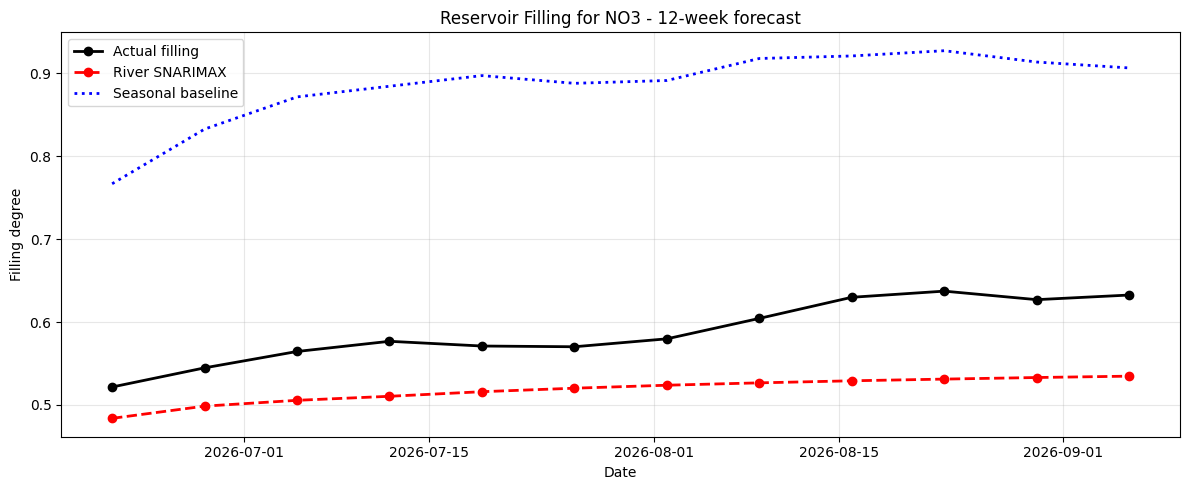

In [15]:
#Now we test how it runs for the coming 12 weeks

predictions, actual, baseline = test_river_forecast(
    reservoir_weekly,
    history_weeks=260,
    horizon=12,
    p=4,
    d=0,
    q=0,
    seasonal_period = 52
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    actual.index,
    actual.values,
    "ko-",
    linewidth=2,
    label="Actual filling"
)

ax.plot(
    predictions.index,
    predictions.values,
    "r--o",
    linewidth=2,
    label="River SNARIMAX"
)

ax.plot(
    baseline.index,
    baseline.values,
    "b:",
    linewidth=2,
    label="Seasonal baseline"
)

ax.set_title("Reservoir Filling for NO3 - 12-week forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Filling degree")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

  

The first prediction was a bit off. Even though it is only for 12 weeks, the seasonal baseline is way off from the predicted values and the actual values. This comes to show that factors may intervene on our data such as external parameters. Asumption may not always prove correct, but this is a start. 

In [16]:

#With this is mind, we do an evaluation to determine a precise comparison

results = pd.DataFrame({
    "Actual": actual,
    "River": predictions,
    "Seasonal_Baseline": baseline
})

results["River_Error"] = (
    results["Actual"] - results["River"]
).abs()

results["Baseline_Error"] = (
    results["Actual"] - results["Seasonal_Baseline"]
).abs()

river_mae = results["River_Error"].mean()
baseline_mae = results["Baseline_Error"].mean()

print(f"River MAE: {river_mae:.4f}")
print(f"Seasonal baseline MAE: {baseline_mae:.4f}")

print(
    f"\nRiver average error: {river_mae * 100:.2f} percentage points"
)
print(
    f"Baseline average error: {baseline_mae * 100:.2f} percentage points"
)

display(results.round(4))


River MAE: 0.0705
Seasonal baseline MAE: 0.2965

River average error: 7.05 percentage points
Baseline average error: 29.65 percentage points


,Actual,River,Seasonal_Baseline,River_Error,Baseline_Error
dato_Id,,,,,
2026-06-21,0.5217,0.4839,0.7668,0.0378,0.2451
2026-06-28,0.5448,0.4986,0.8327,0.0462,0.2879
2026-07-05,0.5645,0.5056,0.8715,0.0589,0.3070
2026-07-12,0.5768,0.5105,0.8843,0.0663,0.3076
2026-07-19,0.5711,0.5160,0.8972,0.0551,0.3261
2026-07-26,0.5702,0.5202,0.8879,0.0500,0.3177
2026-08-02,0.5798,0.5238,0.8913,0.0559,0.3115
2026-08-09,0.6044,0.5267,0.9178,0.0777,0.3134
2026-08-16,0.6299,0.5292,0.9209,0.1007,0.2910


This calculated the error for the River, and it was substantially lower than the seasonal baseline. This means that River captures a general upward trend. It also underestimate the filling levels, as well as that the seasonal baseline performs poorly. 

With this in mind, we can do a simple backtesting to see if River is able to hold across other periods. 

In [17]:
def backtest_river(
    series,
    history_weeks=260,
    horizon=12,
    n_tests=8,
    p=4,
    d=0,
    q=0
):

    results = []

    for test_number in range(n_tests):

        weeks_back = (n_tests - 1 - test_number) * horizon
        
        if weeks_back == 0:
            historical_data = series.copy()
        else:
            historical_data = series.iloc[:-weeks_back].copy()

        predictions, actual, baseline = test_river_forecast(
            historical_data,
            history_weeks=history_weeks,
            horizon=horizon,
            p=p,
            d=d,
            q=q
        )

        river_mae = np.mean(
            np.abs(actual.to_numpy() - predictions.to_numpy())
        )

        baseline_mae = np.mean(
            np.abs(actual.to_numpy() - baseline.to_numpy())
        )

        results.append({
            "Test": test_number + 1,
            "Start": actual.index.min(),
            "End" : actual.index.max(),
            "River_MAE": river_mae,
            "Baseline_MAE": baseline_mae
        })

    return pd.DataFrame(results)

    


In [18]:
#Now we simply run the test to get new results.

backtest_results = backtest_river(
    reservoir_weekly,
    history_weeks=260,
    horizon=12,
    n_tests=8,
    p=4,
    d=0,
    q=0,
)

assert len(backtest_results) == 8

display(backtest_results.round(4))

print("\nNumber of tests confirmed:", len(backtest_results))

print(
    "Average River MAE:",
    round(backtest_results["River_MAE"].mean(),4)
)

print(
    "Average Baseline MAE:",
    round(backtest_results["Baseline_MAE"].mean(), 4)
)

print(
    (
    "River wins in:",
    (backtest_results["River_MAE"] < 
    backtest_results["Baseline_MAE"]).sum(),
    "out of 8 tests"
    )
)

,Test,Start,End,River_MAE,Baseline_MAE
0,1,2024-11-10,2025-01-26,0.0239,0.2888
1,2,2025-02-02,2025-04-20,0.0452,0.3146
2,3,2025-04-27,2025-07-13,0.1539,0.1712
3,4,2025-07-20,2025-10-05,0.0431,0.0958
4,5,2025-10-12,2025-12-28,0.0580,0.0677
5,6,2026-01-04,2026-03-22,0.1715,0.2282
6,7,2026-03-29,2026-06-14,0.0697,0.2683
7,8,2026-06-21,2026-09-06,0.0705,0.2965



Number of tests confirmed: 8
Average River MAE: 0.0795
Average Baseline MAE: 0.2164
('River wins in:', np.int64(8), 'out of 8 tests')


With the backtesting done as well, the River model was evalueated using  8 non-overlapping forecasting periods, with a 12 week forecast and 260 weeks of training history. 

Here the Mean Absolute Error was calculated to 0.0795, which corresponds to 7.95 percentage points for reserovir filling. The baseline achieved and average MAE of 0.2163, or 21.64 percentage points. 

River seemed to outperfromthe baseline in all of the eight periiods, and reduced the forecasting error by roughly 63%. This performance varied between periods, and seasonal changes were more difficult to predict. 

With this is mind, the River model is a promising approach for the forecasting, but I will do additional testing before this is put into Streamlit. 

Below we will test out the different parameters to ensure that the SNARIMAX provides the lowest prediction error. We keep the horizon at 12 weeks to make sure the results are comparable. 

The most recent 24 weeks will be reserved exclusively, as this will prevent selecting model parameters based performance from the final test data. 

In [19]:
#This is the test for model configurations

from itertools import product
from time import perf_counter

#The last most recent data we fish to reserve for now
holdout_weeks = 24
validations_series = reservoir_weekly.iloc[:-holdout_weeks]

#Here we add the parameters we want to compare

history_options = [156, 208, 260]
p_options = [2, 4, 8]

parameter_results = []

for history_weeks, p in product(history_options, p_options):

    start_time = perf_counter()

    tests = backtest_river(
        validations_series,
        history_weeks=history_weeks,
        horizon=12,
        n_tests=4,

        p=p,
        d=0,
        q=0
    )

    parameter_results.append({
        "History_Weeks": history_weeks,
        "p": p,
        "River_MAE": tests["River_MAE"].mean(),
        "Baseline_MAE": tests["Baseline_MAE"].mean(),
        "Runtime_seconds": perf_counter() - start_time
    })


parameter_results = pd.DataFrame(parameter_results)

parameter_results = parameter_results.sort_values(
    "River_MAE"
).reset_index(drop=True)

display(parameter_results.round(4))

,History_Weeks,p,River_MAE,Baseline_MAE,Runtime_seconds
0,260,2,0.0958,0.1407,0.0324
1,260,4,0.1066,0.1407,0.0376
2,208,2,0.1080,0.1407,0.0260
3,208,4,0.1149,0.1407,0.0289
4,260,8,0.1167,0.1407,0.0492
5,208,8,0.2174,0.1407,0.0395
6,156,4,0.3674,0.1407,0.0250
7,156,8,0.3945,0.1407,0.0314
8,156,2,0.4143,0.1407,0.0252


In [20]:
#From the previous results, we now select the best to work with

best_result = parameter_results.iloc[0]

best_history = int(best_result["History_Weeks"])
best_p = int(best_result["p"])

print("Best training history:", best_history, "weeks")
print("Best P-value:", best_p)
print("Validation MAE:", round(best_result["River_MAE"], 4))
print(
    "Runtime",
    round(best_result["Runtime_seconds"], 2),
    "seconds"
)

Best training history: 260 weeks
Best P-value: 2
Validation MAE: 0.0958
Runtime 0.03 seconds


In [21]:
#With the now best values, we evaluate them 

holdout_results = []

n = len(reservoir_weekly)
forecast_origins = [n - 24, n  - 12]

for horizon in [4, 8, 12]:
    for origin_number, origin, in enumerate(forecast_origins, start=1):

        test_data = reservoir_weekly.iloc[:origin + horizon]

        predictions, actual, baseline = test_river_forecast(
            test_data,
            history_weeks=best_history,
            horizon=horizon,
            p=best_p,
            d=0,
            seasonal_period=52
        )

        last_observed = reservoir_weekly.iloc[origin - 1]
        persistence = np.full(horizon, last_observed)

        river_mae = np.mean(
            np.abs(actual.to_numpy() - predictions.to_numpy())
        )

        baseline_mae = np.mean(
            np.abs(actual.to_numpy() - baseline.to_numpy())
        )

        persistence_mae = np.mean(
            np.abs(actual.to_numpy() - persistence)
        )

        holdout_results.append({
            "Horizon": horizon,
            "Origin": origin_number,
            "River_MAE": river_mae,
            "Seasonal_MAE": baseline_mae,
            "Persistence_MAE": persistence_mae
        })

holdout_results = pd.DataFrame(holdout_results)

display(holdout_results.round(4))



,Horizon,Origin,River_MAE,Seasonal_MAE,Persistence_MAE
0,4,1,0.0507,0.2604,0.0477
1,4,2,0.0680,0.2869,0.0591
2,8,1,0.0553,0.2802,0.0511
3,8,2,0.0814,0.3020,0.0738
4,12,1,0.0657,0.2683,0.0744
5,12,2,0.1026,0.2965,0.0955


Average errors by forecast horizon:


,River_MAE,Seasonal_MAE,Persistence_MAE
Horizon,,,
4,0.0593,0.2737,0.0534
8,0.0684,0.2911,0.0625
12,0.0842,0.2824,0.0849


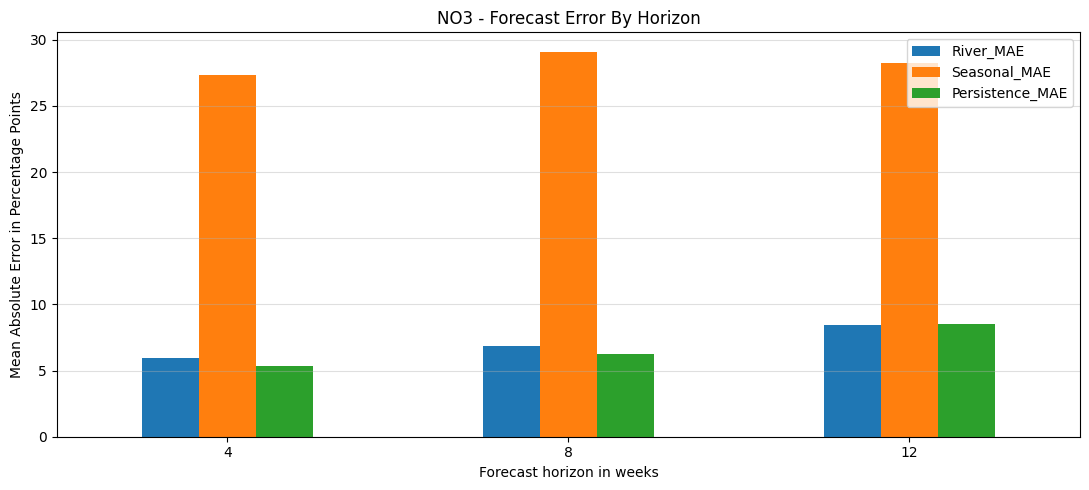

In [22]:
#Now we simply find the average for the two tests for each forecast

holdout_summary = (
    holdout_results
    .groupby("Horizon")[
        ["River_MAE", "Seasonal_MAE", "Persistence_MAE"] 
    ]
    .mean()
)

print("Average errors by forecast horizon:")
display(holdout_summary.round(4))

ax = (holdout_summary.round(4))

ax = (holdout_summary * 100).plot(
    kind="bar",
    figsize=(11,5),
    rot=0
)

ax.set_title("NO3 - Forecast Error By Horizon")
ax.set_xlabel("Forecast horizon in weeks")
ax.set_ylabel("Mean Absolute Error in Percentage Points")
ax.grid(axis="y", alpha=0.4)

plt.tight_layout()
plt.show()



In [23]:
#With all the results sorted out, we can predict the reservoir filling

def forecast_future_river(
    series,
    history_weeks=260,
    horizon=12,
    p=4,
    d=0,
    q=0,
    seasonal_period=52
):

    series = series.sort_index()

    if series.isna().any():
        raise ValueError("Missing reservoir observations. Please correct.")

    if len(series) < history_weeks:
        raise ValueError("Not enough training history. Please improve.")

    training = series.iloc[-history_weeks:]

    model = time_series.SNARIMAX(
        p=p,
        d=d,
        q=q,
        m=seasonal_period,
        sp=1,
        sd=0,
        sq=0
    )


    for value in training:
        model.learn_one(float(value))


    forecast_values = model.forecast(horizon=horizon)

    future_dates = pd.date_range(
        start=training.index[-1] + pd.Timedelta(weeks=1),
        periods=horizon,
        freq="W-SUN"
    )

    return pd.Series(
        np.clip(forecast_values, 0, 1),
        index = future_dates,
        name = "Predicted_Filling"
    )

,Predicted_Filling
2026-09-13,0.6235
2026-09-20,0.6213
2026-09-27,0.6165
2026-10-04,0.6132
2026-10-11,0.6095
2026-10-18,0.6064
2026-10-25,0.6033
2026-11-01,0.6006
2026-11-08,0.5980
2026-11-15,0.5956


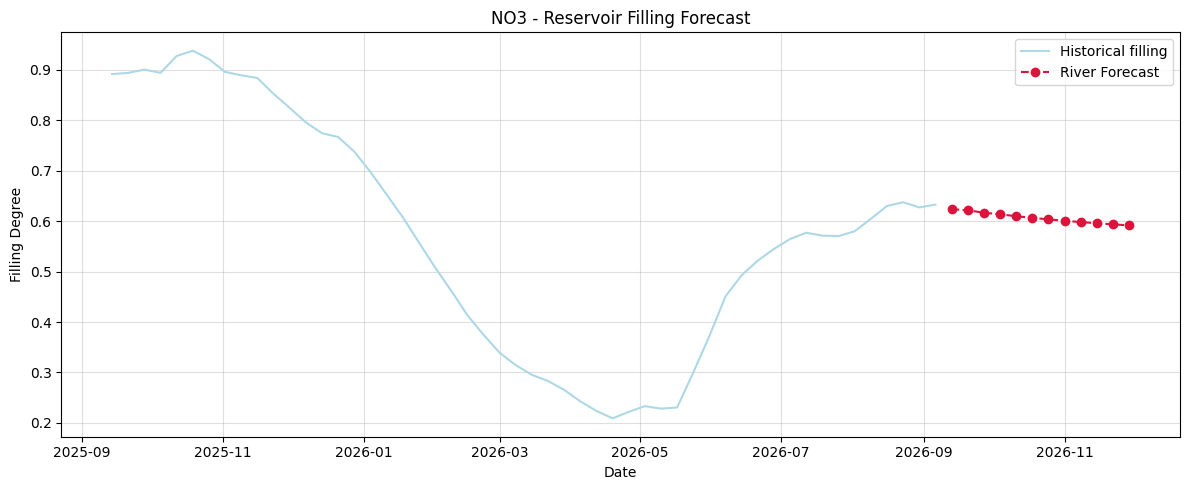

In [24]:
#Finally, we can run the forecast and plot it

future_forecast = forecast_future_river(
    reservoir_weekly,
    history_weeks=best_history,
    horizon=12,
    p=best_p
)

display(future_forecast.to_frame().round(4))

recent_history = reservoir_weekly.iloc[-52:]

plt.figure(figsize=(12,5))

plt.plot(
    recent_history.index,
    recent_history.values,
    label="Historical filling",
    color="lightblue"
)


plt.plot(
    future_forecast.index,
    future_forecast.values,
    label = "River Forecast",
    color="crimson",
    linestyle="--",
    marker="o"
)

plt.title("NO3 - Reservoir Filling Forecast")
plt.xlabel("Date")
plt.ylabel("Filling Degree")
plt.legend()
plt.grid(alpha=0.4)

plt.tight_layout()
plt.show()



Now, with the following testing done;

The River SNarimax configuration used 260 weeks of training, an autoregressive order of p = 2 and a seasonal period of 52 weeks. 

By using 4, 8 and 12 weeks, an independent evaluation was conducted with two historical forecast origins for each horizon in the test. 

River achieved MAE-values of 0,0593, 0,0684 and 0,082 for the given horizons. The errors increased along with the horizon, as it gradually became harder to predict further into the future. 

However,the seasonal baseline performed worse, with values ranging from 0,2737 and 0,2911. Bear in mind, the persistence baseline performed a bit better than River for th 4 to 8 week horizons. 

If we used the 12 week horizon, River put out an MAE of 
0,0842 and 0,0849 for the persistence. The final River model used the most recent reservoir observations and predicted filling levels for the upcoming 12 weeks. This one showed a decline from 62% to 59%. 

Based on these results, River shows promising results, but adding further information such as changes to the weather (precipitation, temperature and or electricity production) may give the model more training background to improve further. 

In [25]:
#Now remains the final step, which is to include the datasources we have been using as well. 

#Here we prepare the additional sources for the weekly resolution, starting with the currency and the existing forecasting

weather_weekly = (
    weather_prepared
    .set_index("time_oslo")
    .sort_index()
)

#Include average measurements across locations so that each hour contributes once to the regional series

weather_hourly = weather_weekly[
    ["precipitation", "temperature_2m"]
].groupby(level=0).mean()

weather_weekly = pd.DataFrame({
    "precipitation": (
        weather_hourly["precipitation"]
        .resample("W-SUN").sum()
    ),
    "temperature":(
        weather_hourly["temperature_2m"]
        .resample("W-SUN").mean()
    )
})
weather_weekly.index = weather_weekly.index.tz_localize(None)

currency_weekly = (
    exchange_rates
    .assign(Date=lambda df: pd.to_datetime(df["Date"]))
    .set_index("Date")
    .sort_index()
    [["EUR_NOK", "USD_NOK"]]
    .resample("W-SUN")
    .last()
)

print("Weather weeks:", len(weather_weekly))
print("Currency weeks:", len(currency_weekly))

display(weather_weekly.head())
display(currency_weekly.head())



Weather weeks: 53
Currency weeks: 53


,precipitation,temperature
time_oslo,,
2024-01-07,2.0,-7.294012
2024-01-14,69.3,2.709524
2024-01-21,8.4,-7.727381
2024-01-28,44.3,2.664881
2024-02-04,77.3,1.741071


,EUR_NOK,USD_NOK
Date,,
2024-01-07,11.3090,10.3553
2024-01-14,11.2765,10.3057
2024-01-21,11.4100,10.4804
2024-01-28,11.3325,10.4245
2024-02-04,11.3870,10.4631


In [26]:
#Second addition is the River forecasting function

def forecast_river_with_sources(
    series,
    input_sources=("reservoir",),
    history_weeks=260,
    horizon=12,
    p=2,
    d=0,
    q=0,
    seasonal_period=52,
    weather_data=None,
    currency_data=None
):

    #Step 1 - Validate selected sources

    allowed_sources = {
        "reservoir", "calendar", "weather", "currency"
    }

    selected = set(input_sources)

    if "reservoir" not in selected:
        raise ValueError("Reservoir history must be selected.")

    if not selected.issubset(allowed_sources):
        raise ValueError(
            f"Unknown sources: {selected - allowed_sources}"
        )
    if history_weeks < 1 or horizon < 1:
        raise ValueError("History and horizon must be positive.")

    # Step 2 - Prepare target series

    series = series.sort_index()

    if len(series) < history_weeks:
        raise ValueError("Insufficient reservoir history")

    training = series.iloc[-history_weeks:]

    if training.isna().any():
        raise ValueError("Missing reservoir observations.")

    #Step 3 - Creating future weekly dates
    future_dates = pd.date_range(
        start=training.index[-1] + pd.Timedelta(weeks=1),
        periods=horizon,
        freq="W-SUN"
    )

    #Step 4 - Add helper function for seasonal calendar features
    def calendar_features(date):
        week = date.isocalendar().week

        angle = 2 * np.pi * week / 52.1775

        return{
            "week_sin": float(np.sin(angle)),
            "week_cos": float(np.cos(angle))
        }

    #Step 5 - Prepare selected external data 
    external = pd.DataFrame(index=training.index)

    if "weather" in selected:
        if weather_data is None:
            raise ValueError("Weather data was not supplied")

        external = external.join(
            weather_data[["precipitation", "temperature"]]
        )

    if "currency" in selected:
        if currency_data is None:
            raise ValueError("Currency data was not supplied")

        external = external.join(
            currency_data[["EUR_NOK", "USD_NOK"]]
        )

    if external.isna().any().any():
        missing_columns = external.columns[
            external.isna().any()
        ].tolist()

        raise ValueError(
            "Selected data sources do not cover the "f" training period. {missing_columns}"
        )

    # Step 6 - Initialize River
    model = time_series.SNARIMAX(
        p=p,
        d=d,
        q=q,
        m=seasonal_period,
        sp=1,
        sd=0,
        sq=0
    )

    # Step 7 - Train using the selected sources

    for date, value in training.items():

        features = {}

        if "calendar" in selected:
            features.update(calendar_features(date))

        if not external.empty:
            features.update(
                external.loc[date].to_dict()
            )
        
        model.learn_one(
            y=float(value),
            x=features
        )

    #Step 8 - Construct features for future dates

    future_features = []

    last_external = (
        external.iloc[-1].to_dict()
        if not external.empty else {}
    )

    for date in future_dates:

        features = {}

        if "calendar" in selected:
            features.update(calendar_features(date))

        features.update(last_external)

        future_features.append(features)


    #9 - Generating the forecast

    forecast_values = model.forecast(
        horizon=horizon,
        xs=future_features
    )

    predictions = pd.Series(
        np.clip(forecast_values, 0, 1),
        index=future_dates,
        name="River Forecast"
    )

    return predictions

In [27]:
#Now we run the source-selection function to see if it displays any promising results

forecast_reservoir = forecast_river_with_sources(
    reservoir_weekly,
    input_sources = ("reservoir",),
    history_weeks=best_history, #reusing the better values from before
    horizon=12,
    p=best_p
)

forecast_calendar = forecast_river_with_sources(
    reservoir_weekly,
    input_sources = ("reservoir", "calendar"),
    history_weeks=best_history,
    horizon=12,
    p=best_p
)

comparison = pd.DataFrame({
    "Reservoir_Only": forecast_reservoir,
    "Reservoir_Calendar": forecast_calendar
})

display(comparison.round(4))

,Reservoir_Only,Reservoir_Calendar
2026-09-13,0.6235,0.5914
2026-09-20,0.6213,0.5602
2026-09-27,0.6165,0.5141
2026-10-04,0.6132,0.4639
2026-10-11,0.6095,0.4060
2026-10-18,0.6064,0.3418
2026-10-25,0.6033,0.2704
2026-11-01,0.6006,0.1926
2026-11-08,0.5980,0.1090
2026-11-15,0.5956,0.0199


In [28]:

source_results = []

n = len(reservoir_weekly)

for source_name, sources in [
    ("Reservoir only", ("reservoir",)),
    ("Reservoir + calendar", ("reservoir", "calendar"))
]:

    for origin in [n - 24, n - 12]:

        # Only observations available at this forecast origin
        history = reservoir_weekly.iloc[:origin]

        # Actual observations for the following 12 weeks
        actual_values = reservoir_weekly.iloc[
            origin:origin + 12
        ]

        predicted_values = forecast_river_with_sources(
            history,
            input_sources=sources,
            history_weeks=best_history,
            horizon=12,
            p=best_p
        )

        error = np.mean(
            np.abs(
                actual_values.to_numpy()
                - predicted_values.to_numpy()
            )
        )

        source_results.append({
            "Input_Sources": source_name,
            "Forecast_Origin": history.index[-1],
            "MAE": error
        })

source_results = pd.DataFrame(source_results)

display(source_results.round(4))

print("\nAverage error by input selection:")

source_summary = (
    source_results
    .groupby("Input_Sources")["MAE"]
    .mean()
    .sort_values()
)

display(source_summary)


,Input_Sources,Forecast_Origin,MAE
0,Reservoir only,2026-03-22,0.0657
1,Reservoir only,2026-06-14,0.1026
2,Reservoir + calendar,2026-03-22,0.1476
3,Reservoir + calendar,2026-06-14,0.0703



Average error by input selection:


Input_Sources
Reservoir only          0.084176
Reservoir + calendar    0.108923
Name: MAE, dtype: float64


As a final extension, additional predictor variables were investigated to determine whether they could improve River's forecasting performance.

Two configurations were evaluated using historical forecasts:

- **Reservoir only:** Average MAE of 0.0842.
- **Reservoir + calendar:** Average MAE of 0.1089.

The reservoir-only configuration achieved the lowest average prediction error. However, the calendar-enhanced model performed better in one of the two individual evaluation periods, suggesting that its usefulness may depend on the forecasting period.

Weekly weather and currency datasets were also prepared successfully, covering approximately 53 weeks in 2024. This was insufficient for evaluation using the selected 260-week training history.

Consequently, weather and currency inputs were retained as optional extensions rather than included in the final comparison.

Overall, the reservoir-only model provided the strongest average performance among the tested configurations. Further evaluation over additional historical periods would be necessary to determine whether external variables could consistently improve forecasting accuracy.